In [1]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('ThreeChamb_Times_CNO.csv')

print(df)

    Group    CS+  Neutral    CS- Control
0       1   39.9    252.3    7.8       n
1       2    0.0    298.7    1.3       n
2       3    4.4    253.9   41.7       n
3       4   54.1    114.8  131.0       n
4       5   20.9    201.1   78.0       n
5       6    2.6    257.7   39.7       n
6       7   55.2    178.4   66.4       y
7       8  110.4     74.6  115.0       y
8       9   29.0     90.1  120.9       y
9      10   60.5     28.1  203.4       y
10     11   12.2     55.0  232.8       y
11     12   29.0    115.8  155.2       y


In [3]:
data = []

for el in df.drop("Group",axis=1).drop("Control",axis=1):
    for i,val in enumerate(df[el]):
        data.append([el,val,df.iloc[i].get('Control')])
        
newdf = (pd.DataFrame(data,columns=['Experimental Condition','Left preference','control']))
print(el)

CS-


/var/folders/b7/k9l5l5ss13d27wd57vb8fq4w0000gn/T/ipykernel_52702/780624237.py:21: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['CS+','Neutral','CS-'],fontsize=30)


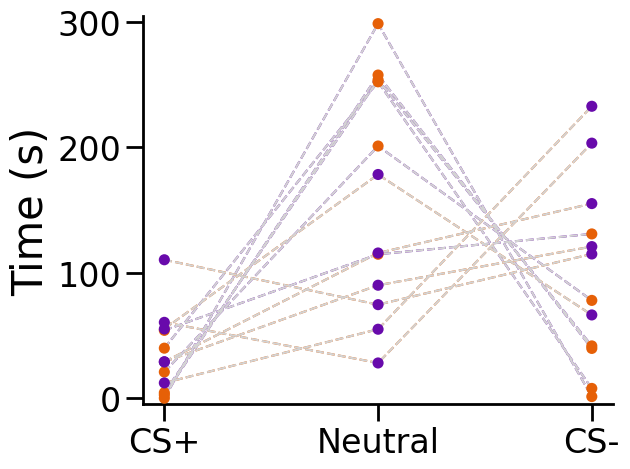

In [6]:
colors = [ '#e66007',"#680aab"]


ax = sns.stripplot(
    data=newdf,
    x='Experimental Condition',
    y='Left preference',
    hue='control',
    jitter=0,
    palette=colors,
    size = 8
)



handles, labels = ax.get_legend_handles_labels()
l = plt.legend(handles[0:2], ["Mock", "SFC"], frameon=False, fontsize=18)
plt.legend().remove()


ax.set_xticklabels(['CS+','Neutral','CS-'],fontsize=30)


###START: CONNECT THE DOTS
df_list = df.values.tolist()

values_x = [0,1,2]

for el in df_list:
    if('y' in el):
        plt.plot(values_x,el[1:-1],color="#e66007", linestyle='--')
    else:
        plt.plot(values_x,el[1:-1],color="#680aab", linestyle='--')
        
for el in df_list:
    if('y' in el):
        plt.plot(values_x,el[1:-1],color="lightgrey", linestyle='--')
    else:
        plt.plot(values_x,el[1:-1],color="lightgrey", linestyle='--')

###END: CONNECT THE DOTS


ax.set_xlabel("Compartments",fontsize=30)
ax.set_xlabel("",fontsize=30)
ax.set_ylabel("Time (s)",fontsize=30)

plt.title("Recall - Three Chamber Arena", fontsize=20,y=1.1)
plt.title("", fontsize=20,y=1.1)

plt.ylim([-5,305])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_linewidth(2)
ax.spines['left'].set_linewidth(2)

ax.tick_params(axis='both', which='major', direction='out',length=12, labelsize=24, width=2)



fig = ax.get_figure()
plt.tight_layout()
fig.tight_layout()
fig.savefig("ThreeChamb_Times_Aligned_CNO.jpg",dpi=600)
plt.savefig('ThreeChamb_Times_Aligned_CNO.eps', dpi=600, format='eps')
